# Car Damage Detection Using YOLO11

## Project Overview

This project aims to detect different types of car damage using
YOLO11 object detection.

The model identifies six types of car damage:

- Dent
- Scratch
- Crack
- Glass Shatter
- Lamp Broken
- Tire Flat

The CARDD dataset is used to train and evaluate the model.

Data augmentation is applied to improve the dataset balance
and help the model learn different variations of car damage.

**Installing required libraries**

In [ ]:
!pip install -q ultralytics kagglehub albumentations

**Importing the required libraries**

In [ ]:
import os
import random
import shutil
from pathlib import Path
import cv2
import yaml
import matplotlib.pyplot as plt
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


**Checking GPU Availability**

In [ ]:
import torch
if torch.cuda.is_available():
    print("GPU is available!")
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("GPU is not available. Using CPU.")

GPU is available!
GPU Name: Tesla T4


**Downloading the dataset**

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("gabrielfcarvalho/cardd-with-yolo-annotations-images-labels")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'cardd-with-yolo-annotations-images-labels' dataset.
Path to dataset files: /kaggle/input/cardd-with-yolo-annotations-images-labels


**Checking the dataset folders**

In [ ]:
import os
print(os.listdir(path))

['data.yaml', 'val', 'test', 'train']


**data.yaml** – contains the dataset configuration and class names.



**train** – training dataset.



**test** – testing dataset.



**val** – validation dataset.

**Checking the training images and labels**

In [ ]:
train_path = os.path.join(path, "train")
print(os.listdir(train_path))

['labels', 'images']


In [ ]:
images_path = os.path.join(train_path, "images")
labels_path = os.path.join(train_path, "labels")
print("Number of training images:", len(os.listdir(images_path)))
print("Number of training labels:", len(os.listdir(labels_path)))

Number of training images: 2816
Number of training labels: 2816


**Check validation and test set**

In [ ]:
#Check the validation dataset
val_path = os.path.join(path, "val")
val_images_path = os.path.join(val_path, "images")
val_labels_path = os.path.join(val_path, "labels")
print("Validation images:", len(os.listdir(val_images_path)))
print("Validation labels:", len(os.listdir(val_labels_path)))
# Check test dataset
test_path = os.path.join(path, "test")
test_images_path = os.path.join(test_path, "images")
test_labels_path = os.path.join(test_path, "labels")
print("\nTest images:", len(os.listdir(test_images_path)))
print("Test labels:", len(os.listdir(test_labels_path)))

Validation images: 810
Validation labels: 810

Test images: 374
Test labels: 374


**Training dataset:** Used to teach the model.



**Validation dataset:** Used to monitor the model during training.



**Test dataset:** Used to evaluate the model after training.

**Reading the dataset configuration**

In [ ]:
yaml_path = os.path.join(path, "data.yaml")
with open(yaml_path, "r") as file:
    data = yaml.safe_load(file)
print(data)

{'train': '/kaggle/input/cardd-with-yolo-annotations-images-labels/train/images', 'val': '/kaggle/input/cardd-with-yolo-annotations-images-labels/val/images', 'test': '/kaggle/input/cardd-with-yolo-annotations-images-labels/test/images', 'nc': 6, 'names': ['dent', 'scratch', 'crack', 'glass shatter', 'lamp broken', 'tire flat']}


**Display the damage classess**

In [ ]:
class_names = data["names"]
print("Number of classes:", len(class_names))
print("\nDamage categories:")
for class_name in class_names:
    print(class_name)

Number of classes: 6

Damage categories:
dent
scratch
crack
glass shatter
lamp broken
tire flat


**Counting Annotations for each damage classess**

In [ ]:
from collections import Counter
# Create a counter to store class counts
class_counts = Counter()
# Get all training label files
label_files = os.listdir(labels_path)
# Count each damage class
for label_file in label_files:
    file_path = os.path.join(labels_path, label_file)
    with open(file_path, "r") as file:
        for line in file:
            class_id = int(line.split()[0])
            class_counts[class_id] += 1
# Display the counts
for class_id, class_name in enumerate(class_names):
    print(class_name, ":", class_counts[class_id])

dent : 1806
scratch : 2560
crack : 651
glass shatter : 475
lamp broken : 494
tire flat : 225


Counter() creates a counter to store the number of occurrences.



os.listdir(labels_path) gets all the label files.



open() reads each label file.



line.split()[0] extracts the class ID from each annotation.



class_counts[class_id] += 1 increases the count for that class.

**Visualizing the class Distribution**

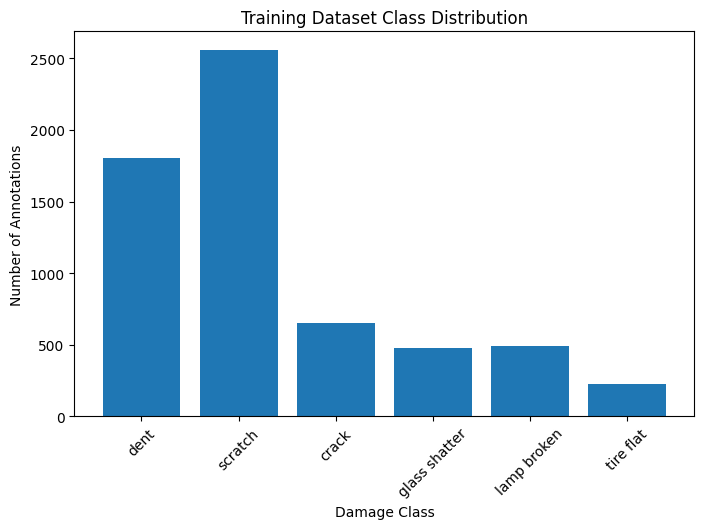

In [ ]:
class_names = list(class_names)
counts = [class_counts[i] for i in range(len(class_names))]
plt.figure(figsize=(8, 5))
plt.bar(class_names, counts)
plt.title("Training Dataset Class Distribution")
plt.xlabel("Damage Class")
plt.ylabel("Number of Annotations")
plt.xticks(rotation=45)
plt.show()

**Display sample training images**

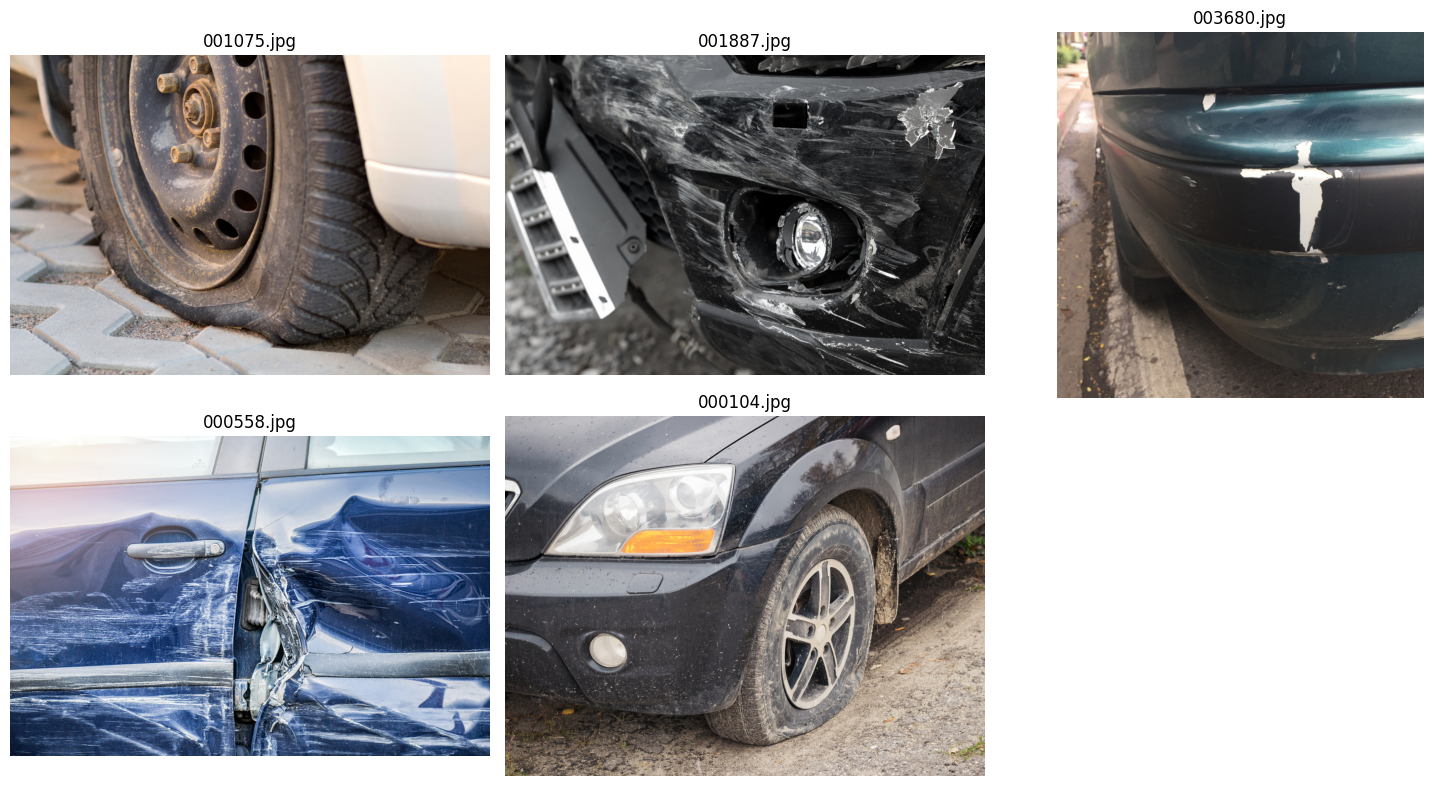

In [ ]:
image_files = os.listdir(images_path)
sample_images = random.sample(image_files, 5)
plt.figure(figsize=(15, 8))
for i, image_name in enumerate(sample_images):
    image_path = os.path.join(images_path, image_name)
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(image_name)
    plt.axis("off")
plt.tight_layout()
plt.show()

**visualize the bounding boxes**

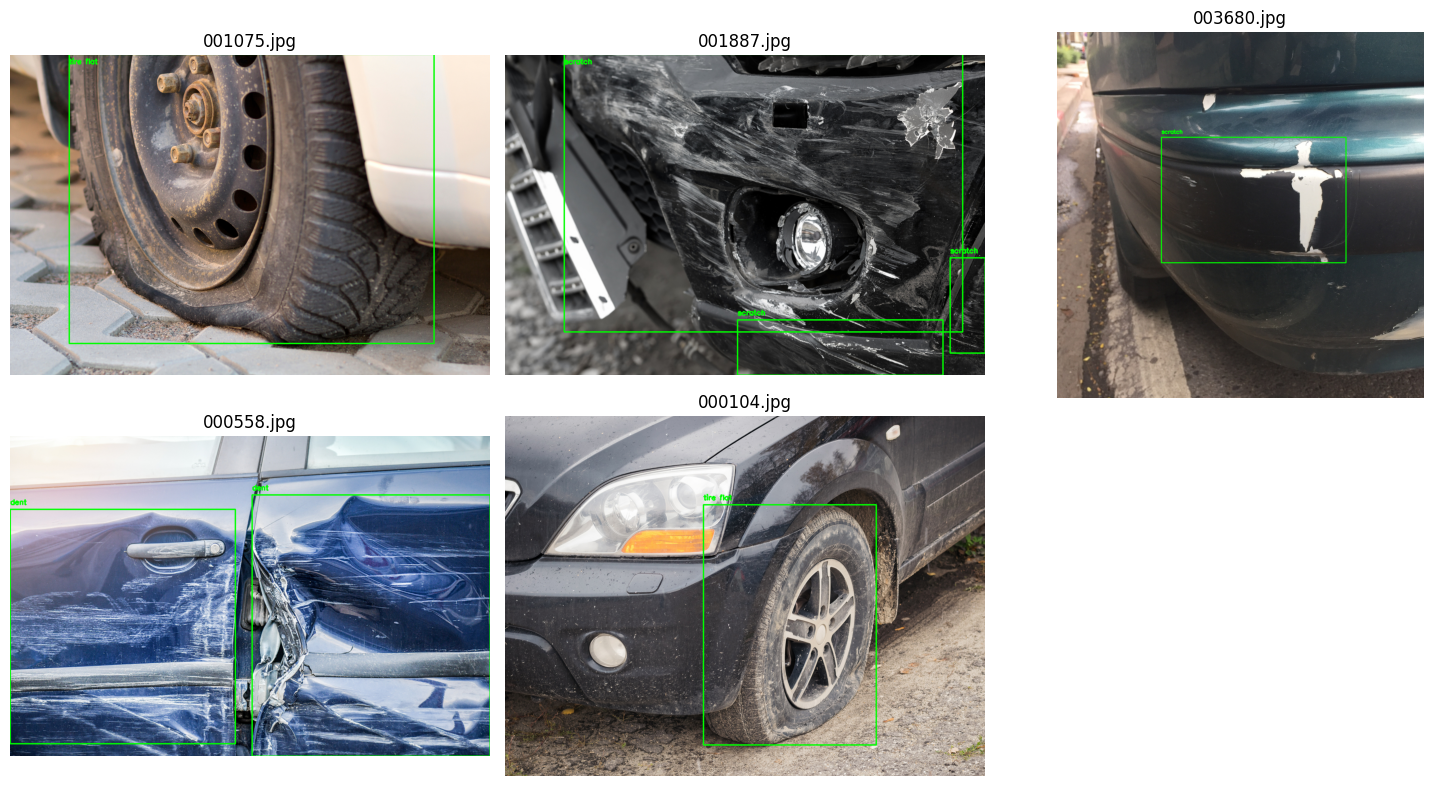

In [ ]:
# Display images with their bounding boxes
plt.figure(figsize=(15, 8))
for i, image_name in enumerate(sample_images):
    # Load image
    image_path = os.path.join(images_path, image_name)
    image = cv2.imread(image_path)
    height, width = image.shape[:2]
    # Find the corresponding label file
    label_name = os.path.splitext(image_name)[0] + ".txt"
    label_path = os.path.join(labels_path, label_name)
    # Read labels
    with open(label_path, "r") as file:
        for line in file:
            values = line.split()
            class_id = int(values[0])
            x_center, y_center, box_width, box_height = map(float, values[1:])
            # Convert normalized coordinates into pixel coordinates
            x1 = int((x_center - box_width / 2) * width)
            y1 = int((y_center - box_height / 2) * height)
            x2 = int((x_center + box_width / 2) * width)
            y2 = int((y_center + box_height / 2) * height)
            # Draw bounding box
            cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
            # Add damage class name
            cv2.putText(
                image,
                class_names[class_id],
                (x1, max(y1 - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (0, 255, 0),
                2
            )
    # Convert BGR to RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    # Display image
    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(image_name)
    plt.axis("off")
plt.tight_layout()
plt.show()

Reading the image and its corresponding label file.



Extracting the damage class and bounding box coordinates.



Converting YOLO's normalized coordinates into pixel coordinates.



Drawing a green rectangle around the damaged area.



Displaying the damage class name.

**validating the Annotations**

In [ ]:
# Check whether the annotations are valid
invalid_labels = []
for split in ["train", "val", "test"]:
    folder = os.path.join(path, split, "labels")
    for label_file in os.listdir(folder):
        file_path = os.path.join(folder, label_file)
        with open(file_path, "r") as file:
            for line in file:
                values = line.split()
                if len(values) != 5:
                    invalid_labels.append(label_file)
                    break
                class_id = int(values[0])
                x, y, w, h = map(float, values[1:])
                if class_id < 0 or class_id >= len(class_names):
                    invalid_labels.append(label_file)
                    break
                if not (0 <= x <= 1 and 0 <= y <= 1):
                    invalid_labels.append(label_file)
                    break
                if not (0 < w <= 1 and 0 < h <= 1):
                    invalid_labels.append(label_file)
                    break
print("Invalid annotation files:", len(invalid_labels))
if len(invalid_labels) == 0:
    print("All annotations are valid!")

Invalid annotation files: 0
All annotations are valid!


We check all three folders: train, val, and test.



Each annotation must contain 5 values.



The class ID must be within our six classes.



The coordinates must be between 0 and 1.



The bounding-box width and height must be greater than zero.

**Counting the images containing each damage class**

In [ ]:
class_image_counts = Counter()
for label_file in os.listdir(labels_path):
    file_path = os.path.join(labels_path, label_file)
    with open(file_path, "r") as file:
        classes_in_image = set()
        for line in file:
            class_id = int(line.split()[0])
            classes_in_image.add(class_id)
        for class_id in classes_in_image:
            class_image_counts[class_id] += 1
# Display the counts
for class_id, class_name in enumerate(class_names):
    print(class_name, ":", class_image_counts[class_id], "images")

dent : 1242 images
scratch : 1507 images
crack : 434 images
glass shatter : 469 images
lamp broken : 489 images
tire flat : 219 images


set() stores unique class IDs in an image.



If an image contains multiple dents, we count that image only once for the dent class.



Counter() stores the total number of images containing each class.



We are checking only the training dataset.

**Visualizing image-level class distribution**

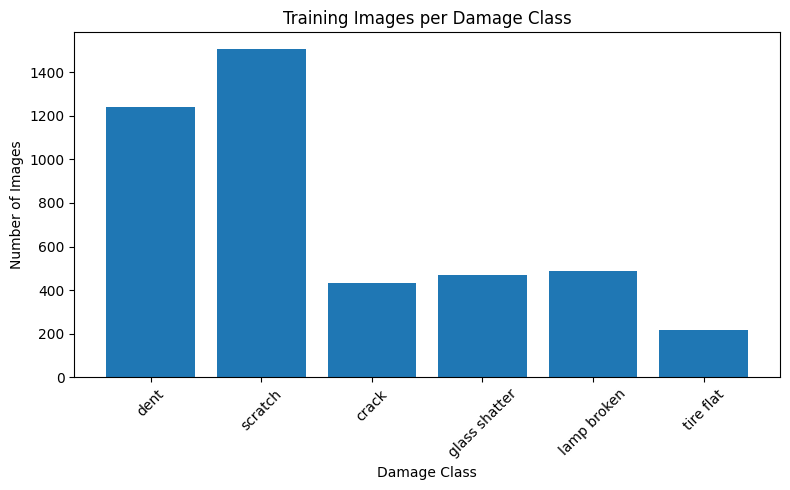

In [ ]:
counts = [class_image_counts[i] for i in range(len(class_names))]
plt.figure(figsize=(8, 5))
plt.bar(class_names, counts)
plt.title("Training Images per Damage Class")
plt.xlabel("Damage Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Data Augmentation

Data augmentation is a technique used to create new variations of training images by applying transformations such as flipping, rotation, brightness adjustment, and scaling.

It helps the model learn different variations of car damage and can improve its ability to generalize to unseen images.

In [ ]:
import albumentations as A
print("Albumentations imported successfully!")

Albumentations imported successfully!


albumentations is a library used for image augmentation.



import albumentations as A allows us to use its functions with the shorter name A.

If we flip or rotate the image, the bounding box must also move or rotate accordingly.

That's why we use Albumentations. It can transform both:
1. The image.
2. The corresponding bounding boxes.
If we change the image but leave the bounding box in its original location, the model will receive incorrect training information.

**Creating augmention transformations**

In [ ]:
transform = A.Compose(
    [
        A.HorizontalFlip(p=0.5),
        A.RandomBrightnessContrast(p=0.4),
        A.Rotate(limit=5, p=0.4),
        A.Affine(scale=(0.9, 1.1), translate_percent=(-0.05, 0.05), p=0.4)
    ],
    bbox_params=A.BboxParams(
        format="yolo",
        label_fields=["class_labels"],
        clip=True,
        filter_invalid_bboxes=True
    )
)

1. HorizontalFlip(p=0.5)

Flips the image horizontally with a 50% probability.

2. RandomBrightnessContrast(p=0.4)

Randomly changes the brightness and contrast with a 40% probability.

3. Rotate(limit=5, p=0.4)

Rotates the image slightly, between -5 and +5 degrees, with a 40% probability.

4. Affine(scale=(0.9, 1.1), translate_percent=(-0.05, 0.05), p=0.4)
- scale → Zooms the image in or out slightly.
- translate_percent → Moves the image slightly in different directions.
- p=0.4 → Applies this transformation with a 40% probability.


**bbox_params**


 Our bounding boxes are in YOLO format.



class_labels contains the class IDs for those bounding boxes.



Whenever the image is transformed, the bounding boxes should also be transformed.

**Apply Augmentation to one image**

take one random training image, read its bounding boxes, apply our transformations, and compare the original image with the augmented image.

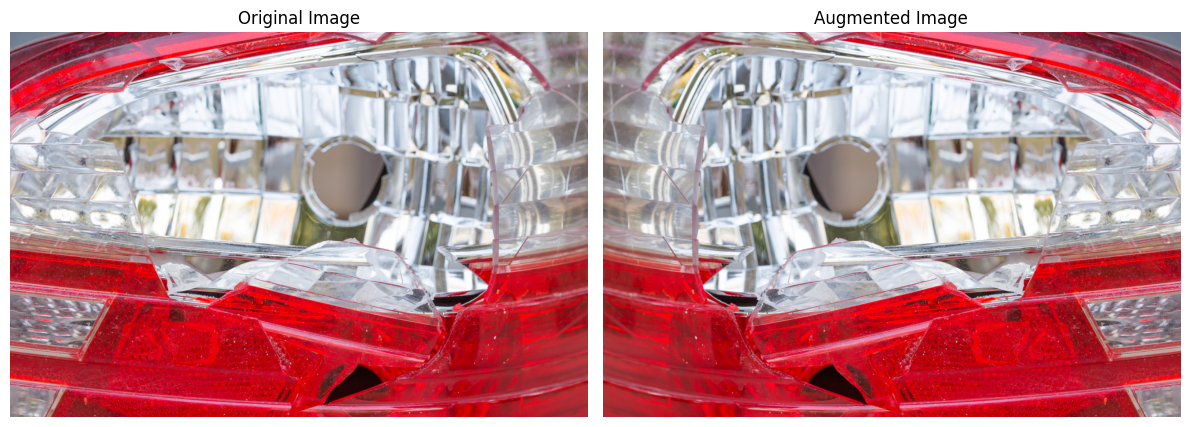

In [ ]:
image_name = random.choice(os.listdir(images_path))
image_path = os.path.join(images_path, image_name)
label_path = os.path.join(
    labels_path,
    image_name.replace(".jpg", ".txt")
)
# Read the image
image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
# Read the bounding boxes and class IDs
bboxes = []
class_labels = []
with open(label_path, "r") as file:
    for line in file:
        values = line.split()
        class_id = int(values[0])
        bbox = list(map(float, values[1:]))
        bboxes.append(bbox)
        class_labels.append(class_id)
# Apply augmentation
augmented = transform(
    image=image,
    bboxes=bboxes,
    class_labels=class_labels
)
# Display original and augmented images
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(augmented["image"])
plt.title("Augmented Image")
plt.axis("off")
plt.tight_layout()
plt.show()

random.choice() selects one random image.



We read its corresponding label file.



bboxes stores the bounding-box coordinates.



class_labels stores the damage class IDs.



transform() applies our augmentation transformations.



plt.imshow() displays the original and augmented images side by side.

**Visualizing the bounding boxes after augmentation**

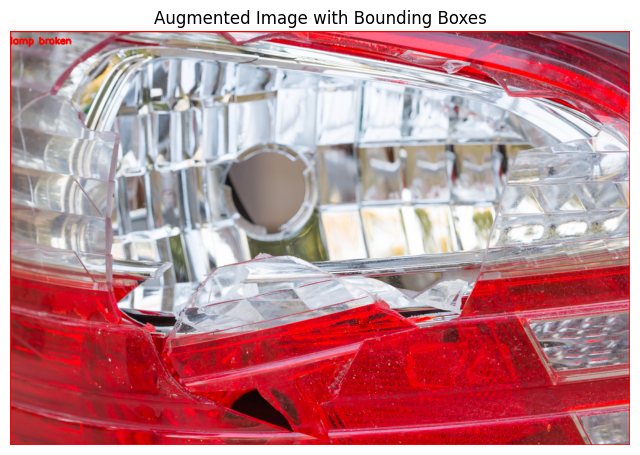

In [ ]:
# Display augmented image with bounding boxes
augmented_image = augmented["image"].copy()
height, width = augmented_image.shape[:2]
for bbox, class_id in zip(augmented["bboxes"], augmented["class_labels"]):
    x_center, y_center, box_width, box_height = bbox
    # Convert YOLO coordinates to pixel coordinates
    x1 = int((x_center - box_width / 2) * width)
    y1 = int((y_center - box_height / 2) * height)
    x2 = int((x_center + box_width / 2) * width)
    y2 = int((y_center + box_height / 2) * height)
    # Draw bounding box
    cv2.rectangle(
        augmented_image,
        (x1, y1),
        (x2, y2),
        (255, 0, 0),
        2
    )
    # Convert class ID to integer
    label = class_names[int(class_id)]
    # Display class name
    cv2.putText(
        augmented_image,
        label,
        (x1, max(y1 - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 0, 0),
        2
    )
# Display image
plt.figure(figsize=(8, 6))
plt.imshow(augmented_image)
plt.title("Augmented Image with Bounding Boxes")
plt.axis("off")
plt.show()

**setting the target number of images should be augmented in minority class**

In [ ]:
# Set the target number of images for minority classes
target_images = 800
# Calculate how many additional images are needed
for class_id, class_name in enumerate(class_names):
    current_count = class_image_counts[class_id]
    additional_images = max(0, target_images - current_count)
    print(
        class_name,
        "-> Current:", current_count,
        "| Additional:", additional_images
    )

dent -> Current: 1242 | Additional: 0
scratch -> Current: 1507 | Additional: 0
crack -> Current: 434 | Additional: 366
glass shatter -> Current: 469 | Additional: 331
lamp broken -> Current: 489 | Additional: 311
tire flat -> Current: 219 | Additional: 581


**creating folder for Augmented images**

In [ ]:
augmented_images_path = "/content/augmented_images"
augmented_labels_path = "/content/augmented_labels"
os.makedirs(augmented_images_path, exist_ok=True)
os.makedirs(augmented_labels_path, exist_ok=True)
print("Augmented image folder created!")
print("Augmented label folder created!")

Augmented image folder created!
Augmented label folder created!


augmented_images_path stores the location where our new images will be saved.



augmented_labels_path stores the location where their corresponding annotation files will be saved.



os.makedirs() creates the folders.



exist_ok=True prevents an error if the folders already exist.

**prepare images for augmentation**

In [ ]:
# Target number of images
target_images = 800
# Minority class IDs
minority_classes = [2, 3, 4, 5]
print("Ready to generate augmented images!")

Ready to generate augmented images!


2 → Crack



3 → Glass shatter



4 → Lamp broken



5 → Tire flat

**Create a function to augment and save one image**

In [ ]:
def augment_image(image_name, class_id):
    # Read image
    image_path = os.path.join(images_path, image_name)
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    # Read labels
    label_path = os.path.join(labels_path, image_name.replace(".jpg", ".txt"))
    boxes = []
    class_labels = []
    with open(label_path, "r") as file:
        for line in file:
            values = line.split()
            class_labels.append(int(values[0]))
            boxes.append([float(x) for x in values[1:]])
    # Apply augmentation
    augmented = transform(image=image, bboxes=boxes, class_labels=class_labels)
    # Save augmented image
    new_image = augmented["image"]
    new_boxes = augmented["bboxes"]
    new_labels = augmented["class_labels"]
    file_name = f"aug_{class_id}_{random.randint(100000, 999999)}.jpg"
    cv2.imwrite(
        os.path.join(augmented_images_path, file_name),
        cv2.cvtColor(new_image, cv2.COLOR_RGB2BGR)
    )
    # Save augmented labels
    with open(os.path.join(augmented_labels_path, file_name.replace(".jpg", ".txt")), "w") as file:
        for label, box in zip(new_labels, new_boxes):
            file.write(f"{int(label)} {' '.join(map(str, box))}\n")
    return new_labels

**Generating Augmented images**

In [ ]:
# Generate augmented images for minority classes
for class_id in minority_classes:
    class_name = class_names[class_id]
    needed = target_images - class_image_counts[class_id]
    generated = 0
    print("\nAugmenting:", class_name)
    while generated < needed:
        # Select a random image
        image_name = random.choice(class_images[class_id])
        # Augment the image
        new_labels = augment_image(image_name, class_id)
        # Check if the target class is present
        if class_id in [int(label) for label in new_labels]:
            generated += 1
    print("Additional images generated:", generated)
print("\nAugmentation completed!")


Augmenting: crack
Additional images generated: 366

Augmenting: glass shatter
Additional images generated: 331

Augmenting: lamp broken
Additional images generated: 311

Augmenting: tire flat
Additional images generated: 581

Augmentation completed!


**verify Augmented files**

In [ ]:
augmented_images = os.listdir(augmented_images_path)
augmented_labels = os.listdir(augmented_labels_path)
print("Augmented images:", len(augmented_images))
print("Augmented labels:", len(augmented_labels))
print("Images without labels:", len(set(
    image.replace(".jpg", ".txt") for image in augmented_images
) - set(augmented_labels)))
print("Labels without images:", len(set(
    label.replace(".txt", ".jpg") for label in augmented_labels
) - set(augmented_images)))

Augmented images: 1589
Augmented labels: 1589
Images without labels: 0
Labels without images: 0


**Combining original and augmented images**

In [ ]:
# Create folders for the final training dataset
final_images_path = "/content/final_train/images"
final_labels_path = "/content/final_train/labels"
os.makedirs(final_images_path, exist_ok=True)
os.makedirs(final_labels_path, exist_ok=True)
print("Final training folders created!")

Final training folders created!


In [ ]:
import shutil
import os
# Copy original training images
for file in os.listdir(images_path):
    shutil.copy2(
        os.path.join(images_path, file),
        os.path.join(final_images_path, file)
    )
# Copy original training labels
for file in os.listdir(labels_path):
    shutil.copy2(
        os.path.join(labels_path, file),
        os.path.join(final_labels_path, file)
    )
# Copy augmented images
for file in os.listdir(augmented_images_path):
    shutil.copy2(
        os.path.join(augmented_images_path, file),
        os.path.join(final_images_path, file)
    )
# Copy augmented labels
for file in os.listdir(augmented_labels_path):
    shutil.copy2(
        os.path.join(augmented_labels_path, file),
        os.path.join(final_labels_path, file)
    )
print("Original and augmented data combined successfully!")

Original and augmented data combined successfully!


Copying the original 2,816 training images.



Copying their original labels.



Copying the 1,589 augmented images.



Copying their corresponding augmented labels.

**Verify final training set**

In [ ]:
# Count final training images and labels
final_images = os.listdir(final_images_path)
final_labels = os.listdir(final_labels_path)
print("Total training images:", len(final_images))
print("Total training labels:", len(final_labels))
print("Images without labels:", len(set(
    image.replace(".jpg", ".txt") for image in final_images
) - set(final_labels)))
print("Labels without images:", len(set(
    label.replace(".txt", ".jpg") for label in final_labels
) - set(final_images)))

Total training images: 4405
Total training labels: 4405
Images without labels: 0
Labels without images: 0


**Create the updated dataset configuration**

We need to tell YOLO where to find:
- Our new augmented training images
- Original validation images
- Original test images
- The 6 damage classes


We will create a new YAML configuration file.

In [ ]:
data_yaml = f"""
train: {final_images_path}
val: {os.path.join(path, 'val', 'images')}
test: {os.path.join(path, 'test', 'images')}
nc: 6
names: {class_names}
"""
with open("/content/augmented_data.yaml", "w") as file:
    file.write(data_yaml)
print("Dataset configuration created successfully!")
print(data_yaml)

Dataset configuration created successfully!

train: /content/final_train/images
val: /kaggle/input/cardd-with-yolo-annotations-images-labels/val/images
test: /kaggle/input/cardd-with-yolo-annotations-images-labels/test/images
nc: 6
names: ['dent', 'scratch', 'crack', 'glass shatter', 'lamp broken', 'tire flat']



**Loading the YOLO model**

In [ ]:
from ultralytics import YOLO
# Load pretrained YOLO11s model
model = YOLO("yolo11s.pt")
print("YOLO model loaded successfully!")

YOLO model loaded successfully!


**Train the YOLO model**

In [ ]:
results = model.train(
    data="/content/augmented_data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    name="car_damage_detection"
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/augmented_data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=car_damage_detection, nbs=64, nms=None, opset=None, optimize

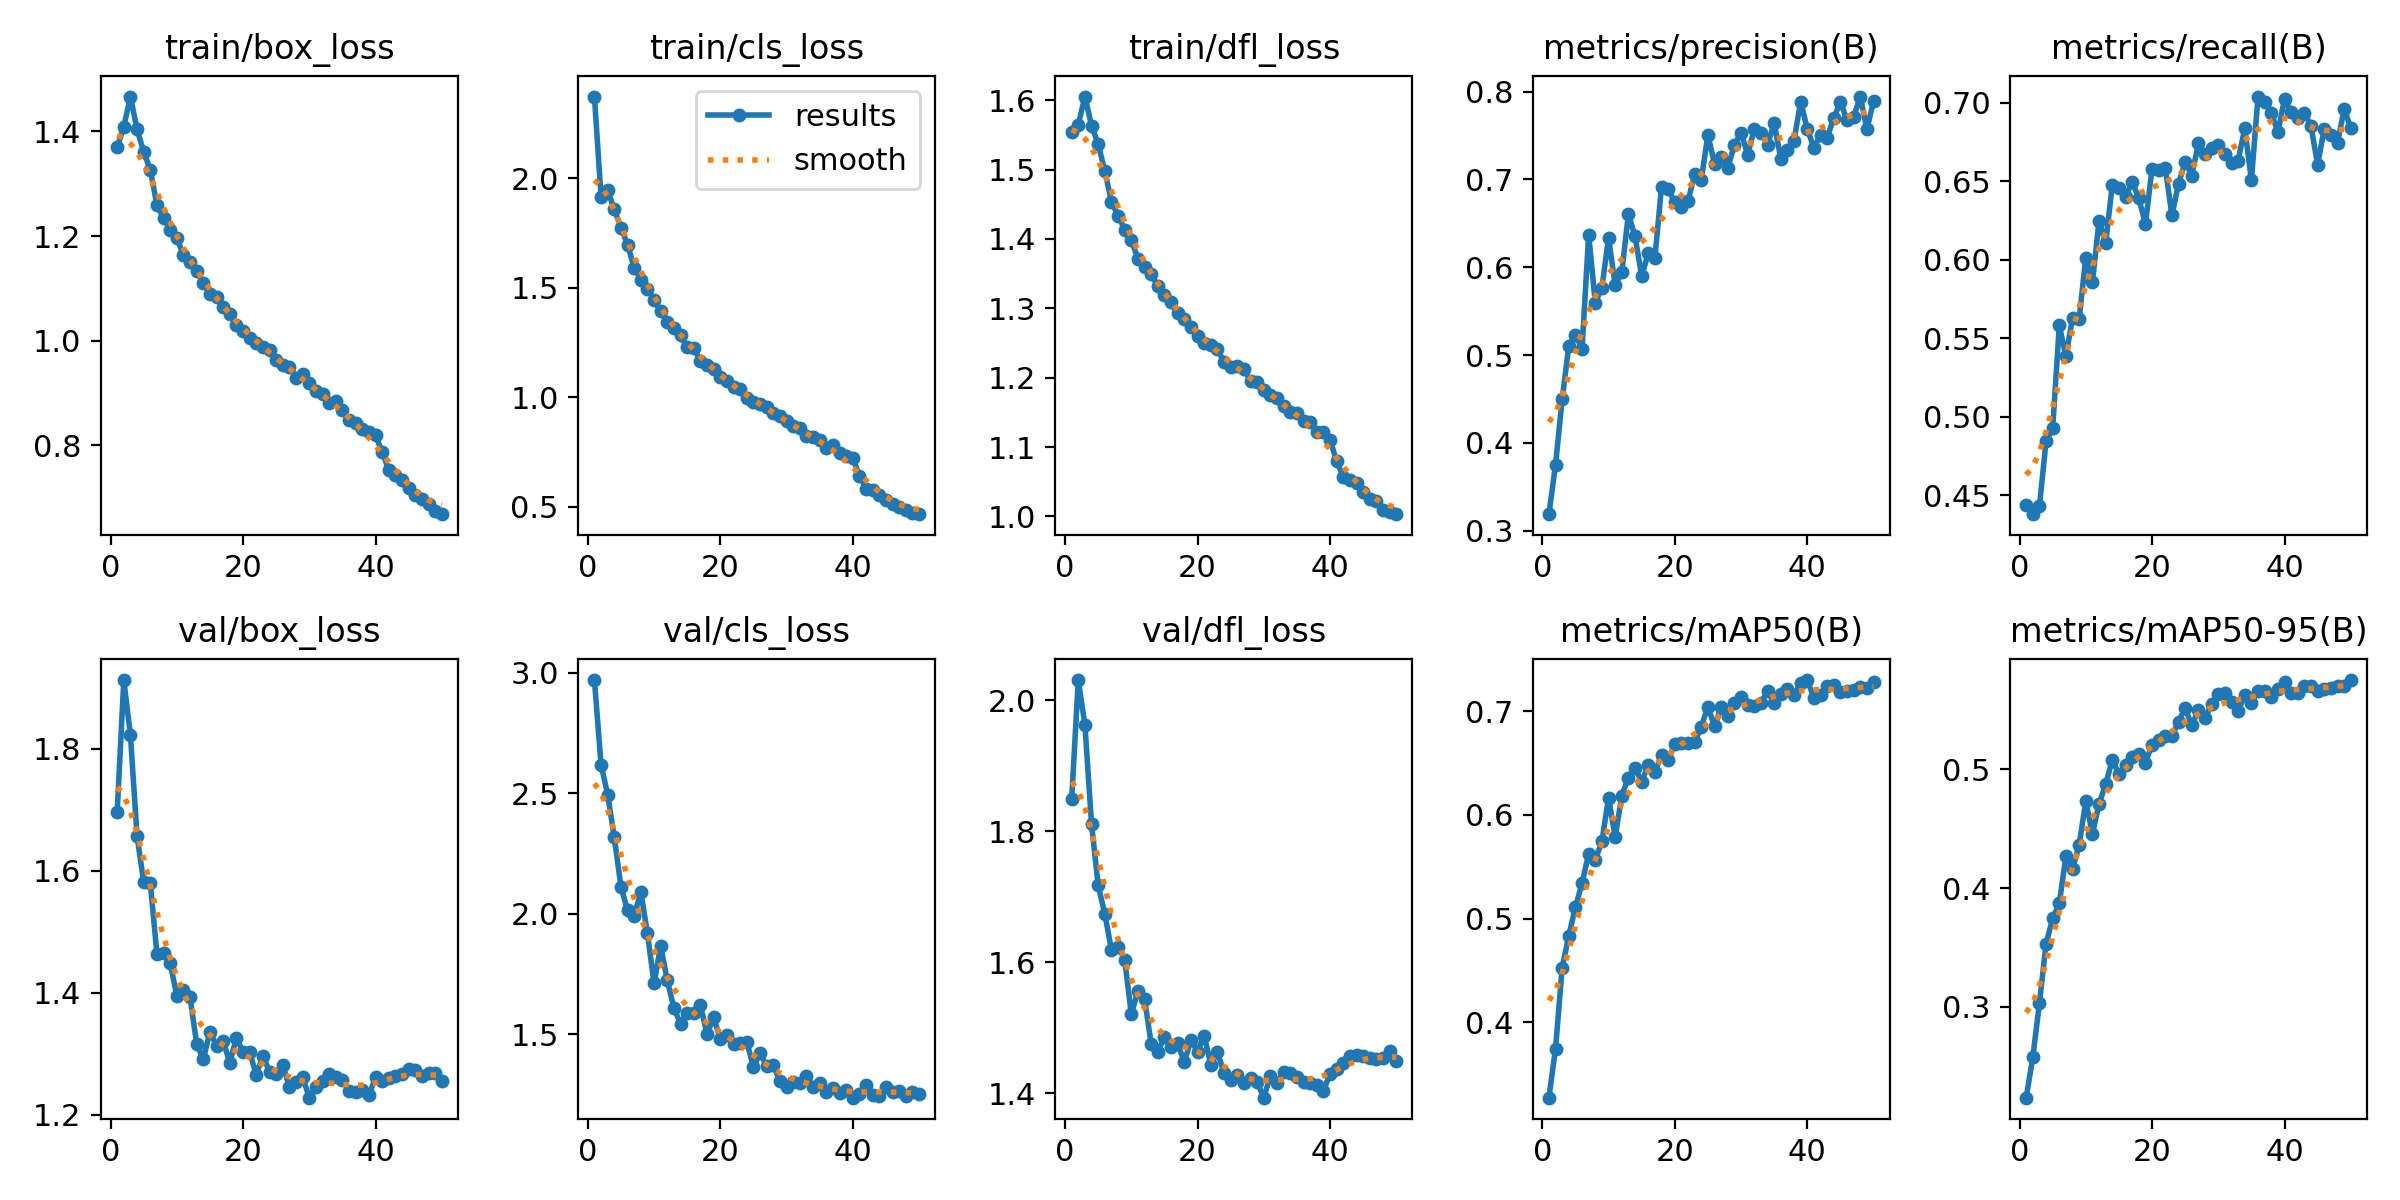

In [ ]:
from IPython.display import Image, display
display(Image(filename="/content/runs/detect/car_damage_detection/results.png"))

In [ ]:
from ultralytics import YOLO
# Load the best trained model
best_model = YOLO("/content/runs/detect/car_damage_detection/weights/best.pt")
# Evaluate on the test dataset
test_results = best_model.val(
    data="/content/augmented_data.yaml",
    split="test"
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,415,122 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 48.3±2.3 MB/s, size: 639.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/cardd-with-yolo-annotations-images-labels/test/labels... 374 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 374/374 65.3it/s 5.7s
WARNING ⚠️ val: Cache directory /kaggle/input/cardd-with-yolo-annotations-images-labels/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.3it/s 7.3s
                   all        374        785      0.768      0.692      0.734      0.581
                  dent        157        236      0.697      0.556      0.605      0.354
 

In [ ]:
print("Test Precision:", test_results.box.mp)
print("Test Recall:", test_results.box.mr)
print("Test mAP50:", test_results.box.map50)
print("Test mAP50-95:", test_results.box.map)

Test Precision: 0.7681920271139475
Test Recall: 0.6920654254897677
Test mAP50: 0.7338148326862534
Test mAP50-95: 0.5813709673649221


In [ ]:
# Predict damage in the uploaded image
results = best_model.predict(
    source="/content/2.jpg",
    conf=0.50,
    iou=0.45,
    save=True
)


image 1/1 /content/2.jpg: 640x448 3 dents, 1 crack, 1 lamp broken, 13.4ms
Speed: 1.8ms preprocess, 13.4ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 448)
Results saved to /content/runs/detect/predict


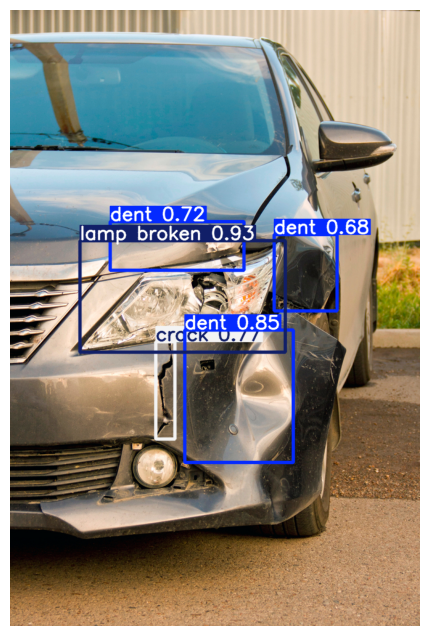

In [ ]:
import matplotlib.pyplot as plt

# Display the predicted image
plt.figure(figsize=(12, 8))

plt.imshow(results[0].plot()[:, :, ::-1])

plt.axis("off")
plt.show()

In [ ]:
import shutil
# Copy the best trained model
shutil.copy(
    "/content/runs/detect/car_damage_detection/weights/best.pt",
    "/content/car_damage_model.pt"
)
print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files
files.download("/content/car_damage_model.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>